# **TD 2: Économétrie appliquée.**

#### Lors de ce deuxième TD, on va étudier l'influence du marché boursier et des variations des taux d'intérêt sur les rendements de 5 actions européennes à l'aide de régressions linéaires et de stress tests. On analysera également l'évolution du bêta glissant de BANQUE_SA sur des fenêtres de 250 jours afin d'étudier la stabilité de sa sensibilité au marché.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [2]:
%matplotlib inline
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "axes.grid": True,
    "grid.alpha": 0.3
})

In [3]:
prix = pd.read_csv("/content/prix_actions.csv", index_col="date", parse_dates=True)
taux = pd.read_csv("/content/taux_interet.csv", index_col="date", parse_dates=True)

In [4]:
for i in [prix, taux]:
  display(i.head(5))

,INDICE_EURO50,LUXE_SA,ENERGIE_SA,BANQUE_SA,PHARMA_SA,UTILITIES_SA
date,,,,,,
2015-01-01,4200.00,140.02,45.00,51.99,78.00,95.01
2015-01-02,4228.19,140.91,44.60,52.74,77.13,95.01
2015-01-05,4215.20,139.15,45.10,53.19,76.26,93.83
2015-01-06,4244.53,136.62,45.67,55.10,75.33,93.24
2015-01-07,4255.94,138.34,46.14,56.30,75.35,93.32


,oat_10a,bund_10a,euribor_3m
date,,,
2000-01-31,5.346,5.170,4.388
2000-02-29,5.345,5.192,4.416
2000-03-31,5.223,5.094,4.429
2000-04-30,5.298,5.170,4.407
2000-05-31,5.317,5.178,4.394


In [5]:
def missing_values(df):
  valeurs_manquantes = df.isna().sum()
  pct_valeurs_manquantes = (100 * valeurs_manquantes / len(df)).round(2)
  table_def = pd.concat(
      [valeurs_manquantes, pct_valeurs_manquantes], axis = 1).set_axis(["Valeurs manquantes", "% de valeurs manquantes"], axis=1).sort_values(by="Valeurs manquantes", ascending=False)
  return table_def

In [6]:
for i in [prix, taux]:
  display(missing_values(i))

,Valeurs manquantes,% de valeurs manquantes
INDICE_EURO50,0,0.0
LUXE_SA,0,0.0
ENERGIE_SA,0,0.0
BANQUE_SA,0,0.0
PHARMA_SA,0,0.0
UTILITIES_SA,0,0.0


,Valeurs manquantes,% de valeurs manquantes
oat_10a,0,0.0
bund_10a,0,0.0
euribor_3m,0,0.0


In [7]:
prix.shape, taux.shape

((2999, 6), (318, 3))

In [8]:
print(f"Les dates des prix vont du {prix.index.min().date()} au {prix.index.max().date()}. Nous avons un ensemble de {len(prix)} observations.")

Les dates des prix vont du 2015-01-01 au 2026-06-30. Nous avons un ensemble de 2999 observations.


In [9]:
print(f"Les dates des taux vont du {taux.index.min().date()} au {taux.index.max().date()}. Le fichier des taux comporte {len(taux)} mois.")

Les dates des taux vont du 2000-01-31 au 2026-06-30. Le fichier des taux comporte 318 mois.


In [10]:
cloture_mensuelle_prix = prix.resample("ME").last()
rendement_mensuel_log = np.log(cloture_mensuelle_prix).diff()

In [11]:
cloture_mensuelle_prix.head(5)

,INDICE_EURO50,LUXE_SA,ENERGIE_SA,BANQUE_SA,PHARMA_SA,UTILITIES_SA
date,,,,,,
2015-01-31,4407.88,143.91,47.38,55.65,74.33,98.54
2015-02-28,4339.81,136.79,45.76,56.59,79.43,91.38
2015-03-31,4284.35,125.94,47.21,53.15,74.44,90.01
2015-04-30,4502.25,139.03,44.73,57.63,77.87,93.48
2015-05-31,4623.46,151.17,42.28,60.96,80.90,93.25


In [12]:
rendement_mensuel_log.head(5)

,INDICE_EURO50,LUXE_SA,ENERGIE_SA,BANQUE_SA,PHARMA_SA,UTILITIES_SA
date,,,,,,
2015-01-31,NaN,NaN,NaN,NaN,NaN,NaN
2015-02-28,-0.015563,-0.050741,-0.034790,0.016750,0.066361,-0.075436
2015-03-31,-0.012862,-0.082641,0.031195,-0.062714,-0.064883,-0.015106
2015-04-30,0.049608,0.098884,-0.053961,0.080925,0.045047,0.037827
2015-05-31,0.026566,0.083715,-0.056330,0.056175,0.038173,-0.002463


In [13]:
banque_sa_clot_m = (pd.concat([cloture_mensuelle_prix[["BANQUE_SA"]].rename(columns={"BANQUE_SA":"Clôture mensuelle BANQUE_SA /"}),
          rendement_mensuel_log[["BANQUE_SA"]].rename(columns={"BANQUE_SA": "Rendement logarithmique."})], axis=1))
banque_sa_clot_m

,Clôture mensuelle BANQUE_SA /,Rendement logarithmique.
date,,
2015-01-31,55.65,NaN
2015-02-28,56.59,0.016750
2015-03-31,53.15,-0.062714
2015-04-30,57.63,0.080925
2015-05-31,60.96,0.056175
...,...,...
2026-02-28,60.59,0.111264
2026-03-31,56.11,-0.076816
2026-04-30,64.50,0.139351


In [14]:
mensuel = rendement_mensuel_log.copy()

On soustrait le taux sans risque aux rendements des actions et de l'indice afin de mesurer la performance obtenue au-delà d'un placement de référence considéré comme sans risque.

Ri-Rf (vu dans le chapitre du MEDAF).

In [15]:
taux_sr = taux["euribor_3m"] / 100 / 12
mensuel = mensuel.sub(taux_sr, axis=0).dropna()

In [16]:
mensuel

,INDICE_EURO50,LUXE_SA,ENERGIE_SA,BANQUE_SA,PHARMA_SA,UTILITIES_SA
date,,,,,,
2015-02-28,-0.015489,-0.050667,-0.034716,0.016824,0.066436,-0.075362
2015-03-31,-0.012703,-0.082483,0.031354,-0.062556,-0.064724,-0.014948
2015-04-30,0.049816,0.099092,-0.053754,0.081133,0.045255,0.038034
2015-05-31,0.026779,0.083929,-0.056117,0.056388,0.038386,-0.002250
2015-06-30,0.018603,0.014391,0.019013,0.035880,0.054166,0.027038
...,...,...,...,...,...,...
2026-02-28,0.040057,0.018595,0.076928,0.109666,0.021461,-0.032687
2026-03-31,-0.028914,-0.122458,0.013361,-0.078416,0.002825,-0.098281
2026-04-30,0.083547,0.088221,0.099548,0.137770,0.040865,0.114801


In [17]:
mensuel["d_oat"] = taux["oat_10a"].diff()
mensuel

,INDICE_EURO50,LUXE_SA,ENERGIE_SA,BANQUE_SA,PHARMA_SA,UTILITIES_SA,d_oat
date,,,,,,,
2015-02-28,-0.015489,-0.050667,-0.034716,0.016824,0.066436,-0.075362,-0.024
2015-03-31,-0.012703,-0.082483,0.031354,-0.062556,-0.064724,-0.014948,-0.002
2015-04-30,0.049816,0.099092,-0.053754,0.081133,0.045255,0.038034,-0.105
2015-05-31,0.026779,0.083929,-0.056117,0.056388,0.038386,-0.002250,-0.013
2015-06-30,0.018603,0.014391,0.019013,0.035880,0.054166,0.027038,0.004
...,...,...,...,...,...,...,...
2026-02-28,0.040057,0.018595,0.076928,0.109666,0.021461,-0.032687,-0.004
2026-03-31,-0.028914,-0.122458,0.013361,-0.078416,0.002825,-0.098281,0.010
2026-04-30,0.083547,0.088221,0.099548,0.137770,0.040865,0.114801,-0.043


In [18]:
display(pd.concat([taux["oat_10a"].rename("OAT_10a_en_%"),
                   taux["oat_10a"].diff().rename("/ variation_en_points_de_%")], axis=1).loc["2015-02":"2015-05"])

,OAT_10a_en_%,/ variation_en_points_de_%
date,,
2015-02-28,1.030,-0.024
2015-03-31,1.028,-0.002
2015-04-30,0.923,-0.105
2015-05-31,0.910,-0.013


In [19]:
print(f"La variable 'mensuel' va du {mensuel.index.min().date()} au {mensuel.index.max().date()}, avec {len(mensuel)} observations.")

La variable 'mensuel' va du 2015-02-28 au 2026-06-30, avec 137 observations.


In [20]:
m_banque = smf.ols("BANQUE_SA ~ INDICE_EURO50 + d_oat", data=mensuel).fit(cov_type="HC3")

Un peu plus haut, nous avons parlé du MEDAF pour expliquer les rendements excédentaires. Ici, on reprend ce principe en ajoutant la variation du taux OAT 10 ans comme deuxième variable explicative. On obtient donc un modèle de régression avec la formule:


$$
r_{i,t}-r_{f,t}=\alpha+\beta(r_{m,t}-r_{f,t})+\gamma\Delta OAT_t+\varepsilon_t
$$


In [21]:
print(m_banque.summary())

                            OLS Regression Results                            
Dep. Variable:              BANQUE_SA   R-squared:                       0.477
Model:                            OLS   Adj. R-squared:                  0.469
Method:                 Least Squares   F-statistic:                     18.73
Date:                Thu, 12 Nov 2026   Prob (F-statistic):           6.73e-08
Time:                        12:42:28   Log-Likelihood:                 181.47
No. Observations:                 137   AIC:                            -356.9
Df Residuals:                     134   BIC:                            -348.2
Df Model:                           2                                         
Covariance Type:                  HC3                                         
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        -0.0067      0.006     -1.084

In [22]:
g = m_banque.params["d_oat"]

In [23]:
print(f"À marché inchangé, +10pb sur l'OAT 10 ans: {g * 0.10:+.1%} pour la banque.")

À marché inchangé, +10pb sur l'OAT 10 ans: +2.2% pour la banque.


In [24]:
scenario = pd.DataFrame({
    "INDICE_EURO50": [0.0, -0.05],
    "d_oat": [0.50, 0.50]
})

In [25]:
print(f"Scénario (marché stable / marché -5%, taux +50pb): ", (m_banque.predict(scenario)*100).round(1).tolist(), "%")

Scénario (marché stable / marché -5%, taux +50pb):  [10.5, 4.5] %


Scénario A: Ra = -0.00665 + (1.2081 *0) + (0.2235 * 0.50)

Scénario B: Rb = -0.00665 + (1.2081 * -0.05) + (0.2235 * 0.50)


Et pour les autres actions ?

In [26]:
actions = [c for c in prix.columns if c not in ["BANQUE_SA", "INDICE_EURO50"]]

In [27]:
for action in actions:
    modele_action = smf.ols(f"{action} ~ INDICE_EURO50 + d_oat", data=mensuel).fit(cov_type="HC3")

    print(f"\n{action}\n")
    print(modele_action.summary().tables[1])

    g_action = modele_action.params["d_oat"]

    print(f"\nÀ marché inchangé, +10pb sur l'OAT 10 ans : {g_action*0.10:+.1%} pour {action}.")

    predictions_action = modele_action.predict(scenario)

    scenario_a_action = predictions_action.iloc[0] # Marché stable, OAT +50pb
    scenario_b_action = predictions_action.iloc[1] # Marché -5%, OAT +50pb

    print(f"\nScénario A : {scenario_a_action:+.2%}")
    print(f"Scénario B : {scenario_b_action:+.2%}\n")


LUXE_SA

                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept         0.0011      0.006      0.190      0.850      -0.010       0.013
INDICE_EURO50     1.3216      0.116     11.365      0.000       1.094       1.550
d_oat             0.0789      0.083      0.948      0.343      -0.084       0.242

À marché inchangé, +10pb sur l'OAT 10 ans : +0.8% pour LUXE_SA.

Scénario A : +4.06%
Scénario B : -2.55%


ENERGIE_SA

                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        -0.0015      0.006     -0.253      0.800      -0.013       0.010
INDICE_EURO50     1.2027      0.162      7.424      0.000       0.885       1.520
d_oat            -0.0328      0.078     -0.423      0.672      -0.185       0.119

À marché inchangé, +10pb sur l'OAT 10 ans : -0.3%

Les 4 actions présentent des betas significatifs, ici on utilise pas le t de student mais plutôt une loi normale pour voir si c'est significatif. Tous les z sont supérieur à 1.96 en valeur absolue. On rejette H0 pour les 4 actions: le coefficient de marché est statistiquement significatifs.


Pour LUXE_SA et ENERGIE_SA, les betas sont supérieurs à 1, ce qui montrent qu'elles sont plus sensibles aux variations du marché. Pour les deux autres ils sont inférieurs à 1.


Et les taux dans tout ça ? Analysons les coefficients gamma.

LUXE_SA:

*   coef +0.0789
*   pvalue: 0.343

Bilan: le coefficient positif indique d'une hausse des taux serait associée à une hausse du rendement de l'action. Mais la pvalue > 0.05, donc on ne peut pas affirmer que cette relation est statistiquement significative.

Pour ENERGIE_SA et PHARMA_SA, les coefficients sont négatifs mais les pvalues ne sont pas statistiquement significatives.

UTILITIES_SA:

*   coef: -0.1519
*   pvalue: 0.001

Bilan: Ici la pvalue est inférieur à 0.05, on rejette donc l'hypothèse H0. On peut conclure qu'il existe une relation négative et statistiquement significative entre les variations de l'OAT et les rendements excédentaire de l'action au seuil de 5%, à marché inchangé. Une hausse de 10pb signifierait une diminution estimée d'environ 1.52%, à marché inchangé.

### Le paramètre est-il stable ? Le cas: BANQUE_SA

In [28]:
from statsmodels.regression.rolling import RollingOLS

In [29]:
rdt = np.log(prix).diff().dropna() #rappel td1

In [30]:
rdt[["INDICE_EURO50", "BANQUE_SA"]].head(5).round(5) #rappel td1

,INDICE_EURO50,BANQUE_SA
date,,
2015-01-02,0.00669,0.01432
2015-01-05,-0.00308,0.00850
2015-01-06,0.00693,0.03528
2015-01-07,0.00268,0.02154
2015-01-08,-0.00664,0.00461


In [31]:
modele = smf.ols("BANQUE_SA ~ INDICE_EURO50", data=rdt).fit() #rappel td1

Ici on reprend le modèle de regression du TD1 afin de comparer le beta global estimé sur l'ensemble des rendements quotidiens, aux betas glissants calculés sur des fenêtres de 250 jours. Cela permet de voir si la sensibilité de l'action BANQUE_SA au marché reste stable au cours du temps.

In [32]:
#rappel td1:
print(f"Beta quotidien sur toutes les observations: {modele.params["INDICE_EURO50"]:.3F}")
print(f"Alpha quotidien: {modele.params["Intercept"]:.5f}")
print(f"R squared des observations: {modele.rsquared:.1%}")

Beta quotidien sur toutes les observations: 1.339
Alpha quotidien: -0.00017
R squared des observations: 46.5%


In [33]:
X = sm.add_constant(rdt["INDICE_EURO50"])
glissant = RollingOLS(rdt["BANQUE_SA"], X, window=250).fit()
beta_g = glissant.params["INDICE_EURO50"]
se_g = glissant.bse["INDICE_EURO50"]

In [34]:
beta_g.tail(2)

,INDICE_EURO50
date,
2026-06-29,1.196291
2026-06-30,1.183360


In [35]:
print(f"Beta quotidien sur toutes les observations: {modele.params["INDICE_EURO50"]:.3F}")
print(f"Min. des betas glissants: {beta_g.min():.2f}")
print(f"Max. des betas glissants: {beta_g.max():.3f}")
print(f"Dernier beta glissant: {beta_g.iloc[-1]:.3f}")

Beta quotidien sur toutes les observations: 1.339
Min. des betas glissants: 1.11
Max. des betas glissants: 1.593
Dernier beta glissant: 1.183


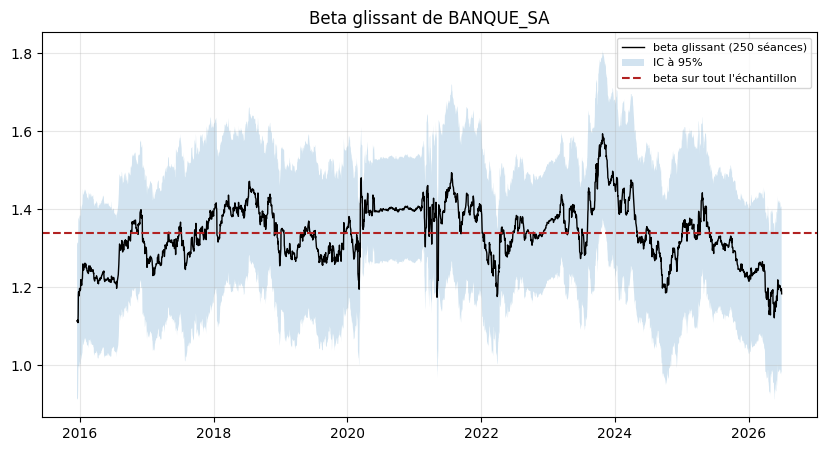

In [36]:
fig, ax = plt.subplots()
ax.plot(beta_g.index, beta_g, color= "black", lw=1, label= "beta glissant (250 séances)")
ax.fill_between(beta_g.index, beta_g - 1.96 * se_g, beta_g + 1.96 * se_g, alpha= 0.2, label= "IC à 95%")
ax.axhline(modele.params["INDICE_EURO50"], color= "firebrick", ls= "--", label = "beta sur tout l'échantillon")
ax.set_title("Beta glissant de BANQUE_SA")
ax.legend(fontsize=8)
plt.show()


In [37]:
resume_beta = beta_g.dropna().describe()
print(resume_beta.rename("beta glissant").to_frame().round(3))

       beta glissant
count       2749.000
mean           1.338
std            0.075
min            1.110
25%            1.288
50%            1.338
75%            1.395
max            1.593


Le beta est systématiquement supérieur à 1. L'écart type qui mesure toute l'observation est assez faible, la sensibilité du marché ne change pas énormement au cours du temps. On peut donc considérer que le bêta est relativement stable sur la période étudiée, mais les statistiques descriptives ne suffisent pas à conclure à sa fiabilité statistique. Il faudrait également examiner les erreurs standards et les intervalles de confiance des estimations.

In [38]:
borne_inf = beta_g - 1.96 * se_g
borne_sup = beta_g + 1.96 * se_g

valides = beta_g.notna() & se_g.notna()

part = (borne_inf[valides] > 1).mean() * 100

print(f"Part des IC entièrement supérieurs à 1: {part:.1f}%")

Part des IC entièrement supérieurs à 1: 96.1%


Pour 96.1% des fenêtres glissantes de 250 jours, la borne inférieure de l'intervalle de confiance à 95% est supérieure à 1. Mais on pouvait déjà observer cette tendance visuellement sur le graphique du beta glissant.